**Author:** Tianqi Shen & Runze Shi & GPT-5

**Date:** 19 September 2026

# Motivation Experiment on Shakespeare
## LLM-pretraining Experiments

We compare three optimizers on the Shakespeare dataset: AdamW, Muon with a fixed learning rate, and Muon with a tuned LR scheduler (Muon+decay). Each optimizer has four learning rates, giving 12 loss curves in total. Train and validation losses are recorded every two iterations and read directly from the corresponding CSV files. This experiment does not use an optimizer switch, so no curve concatenation is needed.

In [1]:
%matplotlib inline
#import matplotlib_inline   # setup output image format, do not use 'svg' if need 'pdf' output
#matplotlib_inline.backend_inline.set_matplotlib_formats('svg')
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 300
import matplotlib
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.patches import Rectangle, ConnectionPatch

### Define colors for plotting

In [2]:
colors = {  # Algorithms to plot + their colors
    # AdamW: blue shades
    "AdamW (lr=9e-4)": "#08306b",
    "AdamW (lr=1e-3)": "#2171b5",
    "AdamW (lr=2e-3)": "#6baed6",
    "AdamW (lr=3e-3)": "#bdd7e7",

    # Muon with a fixed learning rate: crimson/red shades
    "Muon (lr=6e-2)": "#67000d",
    "Muon (lr=7e-2)": "#a50f15",
    "Muon (lr=8e-2)": "#cb181d",
    "Muon (lr=9e-2)": "#fb6a4a",

    # Muon with an LR scheduler: orange shades
    "Muon+decay (lr=6e-2)": "#8c2d04",
    "Muon+decay (lr=7e-2)": "#d94801",
    "Muon+decay (lr=8e-2)": "#f16913",
    "Muon+decay (lr=9e-2)": "#fd8d3c",

    # Aggregated curves
    "AdamW": "#2171b5",
    "Muon": "#a50f15",
    "Muon+decay": "#f16913",
}

methods = [
    "AdamW (lr=9e-4)",
    "AdamW (lr=1e-3)",
    "AdamW (lr=2e-3)",
    "AdamW (lr=3e-3)",
    "Muon (lr=6e-2)",
    "Muon (lr=7e-2)",
    "Muon (lr=8e-2)",
    "Muon (lr=9e-2)",
    "Muon+decay (lr=6e-2)",
    "Muon+decay (lr=7e-2)",
    "Muon+decay (lr=8e-2)",
    "Muon+decay (lr=9e-2)",
]

### Define data paths and column names

In [3]:
val_path = "llm_pretrain_lr_scheduler/motivation-shakespeare-val.csv"
train_path = "llm_pretrain_lr_scheduler/motivation-shakespeare-train.csv"

col_map_val = {  # Column names in the CSV file
    "AdamW (lr=9e-4)": "shakespeare_3_2adamw9e4 - val/loss",
    "AdamW (lr=1e-3)": "shakespeare_3_adamw1e3 - val/loss",
    "AdamW (lr=2e-3)": "shakespeare_3_2adamw2e3 - val/loss",
    "AdamW (lr=3e-3)": "shakespeare_3_2adamw3e3 - val/loss",
    "Muon (lr=6e-2)": "shakespeare_3_muon6e2 - val/loss",
    "Muon (lr=7e-2)": "shakespeare_3_muon7e2 - val/loss",
    "Muon (lr=8e-2)": "shakespeare_3_muon8e2 - val/loss",
    "Muon (lr=9e-2)": "shakespeare_3_muon9e2 - val/loss",
    "Muon+decay (lr=6e-2)": "shakespeare_3_muon6e2cos3 - val/loss",
    "Muon+decay (lr=7e-2)": "shakespeare_3_muon7e2cos - val/loss",
    "Muon+decay (lr=8e-2)": "shakespeare_3_muon8e2cos - val/loss",
    "Muon+decay (lr=9e-2)": "shakespeare_3_muon9e2cos - val/loss",
}

col_map_train = {  # Column names in the CSV file
    "AdamW (lr=9e-4)": "shakespeare_3_2adamw9e4 - train/loss",
    "AdamW (lr=1e-3)": "shakespeare_3_adamw1e3 - train/loss",
    "AdamW (lr=2e-3)": "shakespeare_3_2adamw2e3 - train/loss",
    "AdamW (lr=3e-3)": "shakespeare_3_2adamw3e3 - train/loss",
    "Muon (lr=6e-2)": "shakespeare_3_muon6e2 - train/loss",
    "Muon (lr=7e-2)": "shakespeare_3_muon7e2 - train/loss",
    "Muon (lr=8e-2)": "shakespeare_3_muon8e2 - train/loss",
    "Muon (lr=9e-2)": "shakespeare_3_muon9e2 - train/loss",
    "Muon+decay (lr=6e-2)": "shakespeare_3_muon6e2cos3 - train/loss",
    "Muon+decay (lr=7e-2)": "shakespeare_3_muon7e2cos - train/loss",
    "Muon+decay (lr=8e-2)": "shakespeare_3_muon8e2cos - train/loss",
    "Muon+decay (lr=9e-2)": "shakespeare_3_muon9e2cos - train/loss",
}

### Functional helpers for obtaining curve data

In [4]:
# Helper: load a single curve (x, y)
def get_curve(df, x_col, col_name: str):
    data = df[[x_col, col_name]].copy()
    data[x_col] = pd.to_numeric(data[x_col], errors="coerce")
    data[col_name] = pd.to_numeric(data[col_name], errors="coerce")
    data = data.dropna()
    data = data.sort_values(x_col)
    return data[x_col].to_numpy(), data[col_name].to_numpy()

# Helper: plot only the part within the zoom window on a given axes
def plot_on(ax_like, name, x, y, zoom_x0, zoom_x1):
    m = (x >= zoom_x0) & (x <= zoom_x1)
    ax_like.plot(x[m], y[m], marker="o", markersize=1.5, linewidth=1.2, color=colors[name])

### Validation loss curves

In [5]:
df_val = pd.read_csv(val_path)
print(df_val.columns)
x_col = "iter"
df_val[x_col] = pd.to_numeric(df_val[x_col], errors="coerce")

Index(['iter', 'shakespeare_3_2adamw9e4 - val/loss',
       'shakespeare_3_2adamw9e4 - val/loss__MIN',
       'shakespeare_3_2adamw9e4 - val/loss__MAX',
       'shakespeare_3_2adamw9e4 - _step',
       'shakespeare_3_2adamw9e4 - _step__MIN',
       'shakespeare_3_2adamw9e4 - _step__MAX',
       'shakespeare_3_2adamw3e3 - val/loss',
       'shakespeare_3_2adamw3e3 - val/loss__MIN',
       'shakespeare_3_2adamw3e3 - val/loss__MAX',
       'shakespeare_3_2adamw3e3 - _step',
       'shakespeare_3_2adamw3e3 - _step__MIN',
       'shakespeare_3_2adamw3e3 - _step__MAX',
       'shakespeare_3_2adamw2e3 - val/loss',
       'shakespeare_3_2adamw2e3 - val/loss__MIN',
       'shakespeare_3_2adamw2e3 - val/loss__MAX',
       'shakespeare_3_2adamw2e3 - _step',
       'shakespeare_3_2adamw2e3 - _step__MIN',
       'shakespeare_3_2adamw2e3 - _step__MAX',
       'shakespeare_3_muon9e2cos - val/loss',
       'shakespeare_3_muon9e2cos - val/loss__MIN',
       'shakespeare_3_muon9e2cos - val/loss__MAX',
 

(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)
(751,)


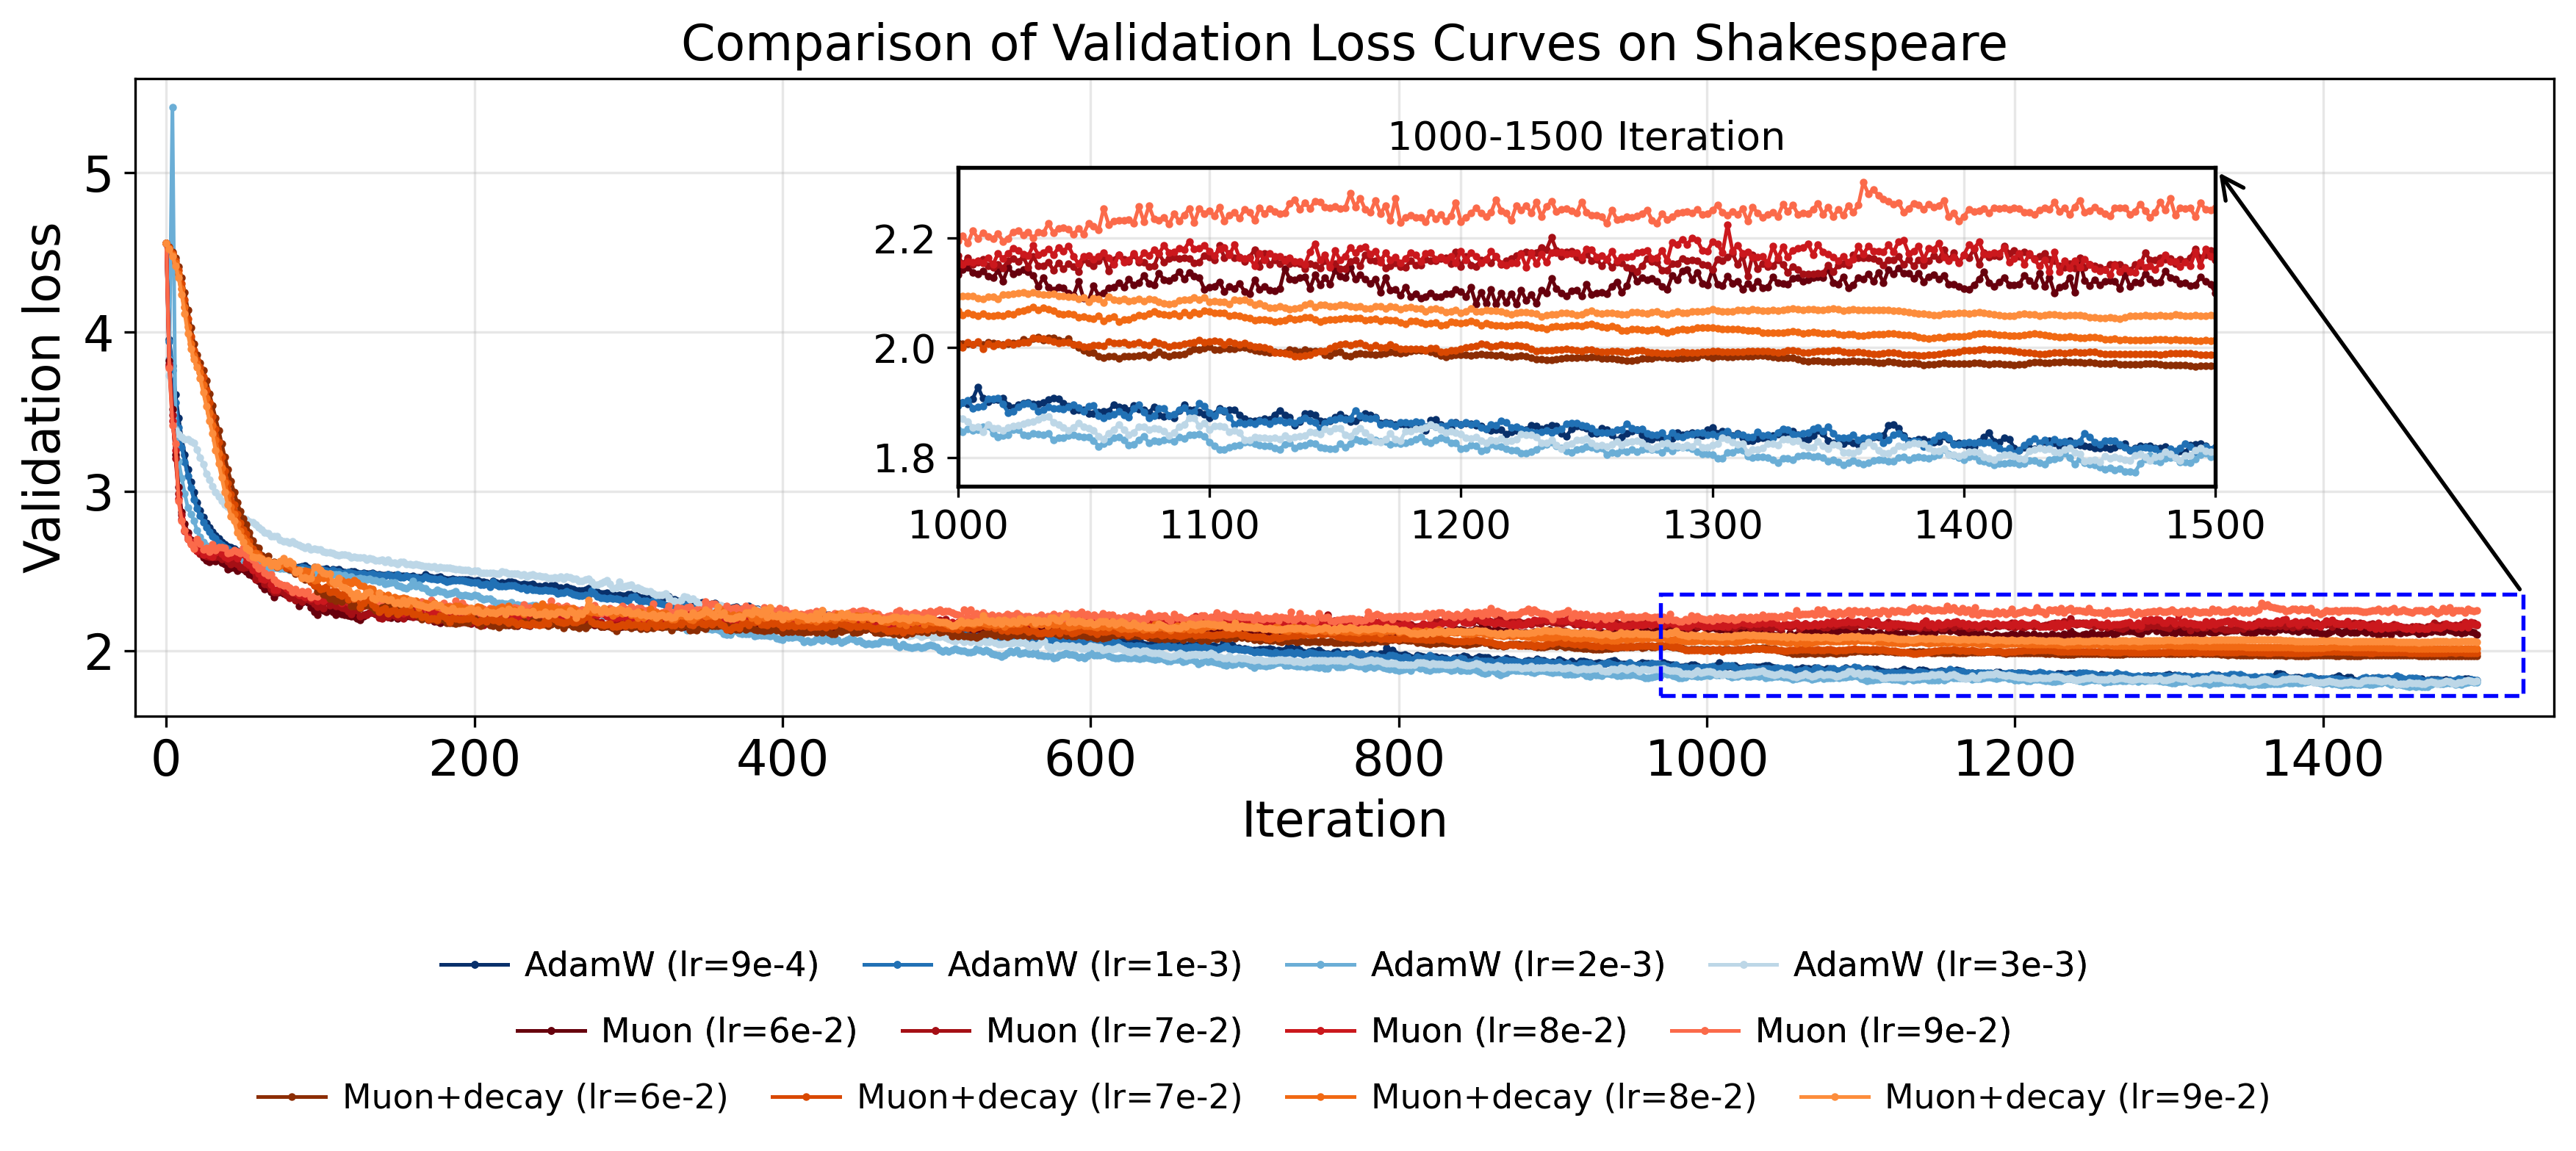

Saved figure to: llm_pretrain_motivation_shakespeare_val.pdf


In [11]:
fig, ax = plt.subplots(figsize=(12, 5))

val_curves = []
for name in methods:
    x, y = get_curve(df_val, x_col, col_map_val[name])
    #print(x.shape)
    #print(y.shape)
    val_curves.append((name, x, y))
    ax.plot(x, y, marker="o", markersize=1.5, linewidth=1.2, label=name, color=colors[name])

ax.set_title("Comparison of Validation Loss Curves on Shakespeare", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Validation loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)

max_iter = int(df_val[x_col].max())
ax.set_xlim(-20.0, float(max_iter) + 50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter

axins = ax.inset_axes([0.34, 0.36, 0.52, 0.50])
for name, x, y in val_curves:
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)

axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)

for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)

all_inset_vals = []
for name, x, y in val_curves:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])

vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin

rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0,
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)

arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),
    coordsA=ax.transData,
    xyB=(1.0, 1.0),
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black",
    shrinkA=2, shrinkB=2, clip_on=False,
)
fig.add_artist(arrow)

fig.tight_layout()
fig.subplots_adjust(bottom=0.34)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = methods[:4]
row2 = methods[4:8]
row3 = methods[8:12]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=11, bbox_to_anchor=(0.5, 0.07), columnspacing=1.3, handletextpad=0.5)
fig.add_artist(leg1)
leg2 = fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
                  fontsize=11, bbox_to_anchor=(0.5, 0.01), columnspacing=1.3, handletextpad=0.5)
fig.add_artist(leg2)
fig.legend([hmap[l] for l in row3], row3, loc="lower center", ncol=len(row3), frameon=False,
           fontsize=11, bbox_to_anchor=(0.5, -0.05), columnspacing=1.3, handletextpad=0.5)

plt.show()
fig.savefig("llm_pretrain_motivation_shakespeare_val.pdf", dpi=300, format="pdf", bbox_inches="tight")
print("Saved figure to: llm_pretrain_motivation_shakespeare_val.pdf")
plt.close()

### Train loss curves

In [7]:
df_train = pd.read_csv(train_path)
print(df_train.columns)
df_train[x_col] = pd.to_numeric(df_train[x_col], errors="coerce")

Index(['iter', 'shakespeare_3_2adamw9e4 - train/loss',
       'shakespeare_3_2adamw9e4 - train/loss__MIN',
       'shakespeare_3_2adamw9e4 - train/loss__MAX',
       'shakespeare_3_2adamw9e4 - _step',
       'shakespeare_3_2adamw9e4 - _step__MIN',
       'shakespeare_3_2adamw9e4 - _step__MAX',
       'shakespeare_3_2adamw3e3 - train/loss',
       'shakespeare_3_2adamw3e3 - train/loss__MIN',
       'shakespeare_3_2adamw3e3 - train/loss__MAX',
       'shakespeare_3_2adamw3e3 - _step',
       'shakespeare_3_2adamw3e3 - _step__MIN',
       'shakespeare_3_2adamw3e3 - _step__MAX',
       'shakespeare_3_2adamw2e3 - train/loss',
       'shakespeare_3_2adamw2e3 - train/loss__MIN',
       'shakespeare_3_2adamw2e3 - train/loss__MAX',
       'shakespeare_3_2adamw2e3 - _step',
       'shakespeare_3_2adamw2e3 - _step__MIN',
       'shakespeare_3_2adamw2e3 - _step__MAX',
       'shakespeare_3_muon9e2cos - train/loss',
       'shakespeare_3_muon9e2cos - train/loss__MIN',
       'shakespeare_3_muon9e2c

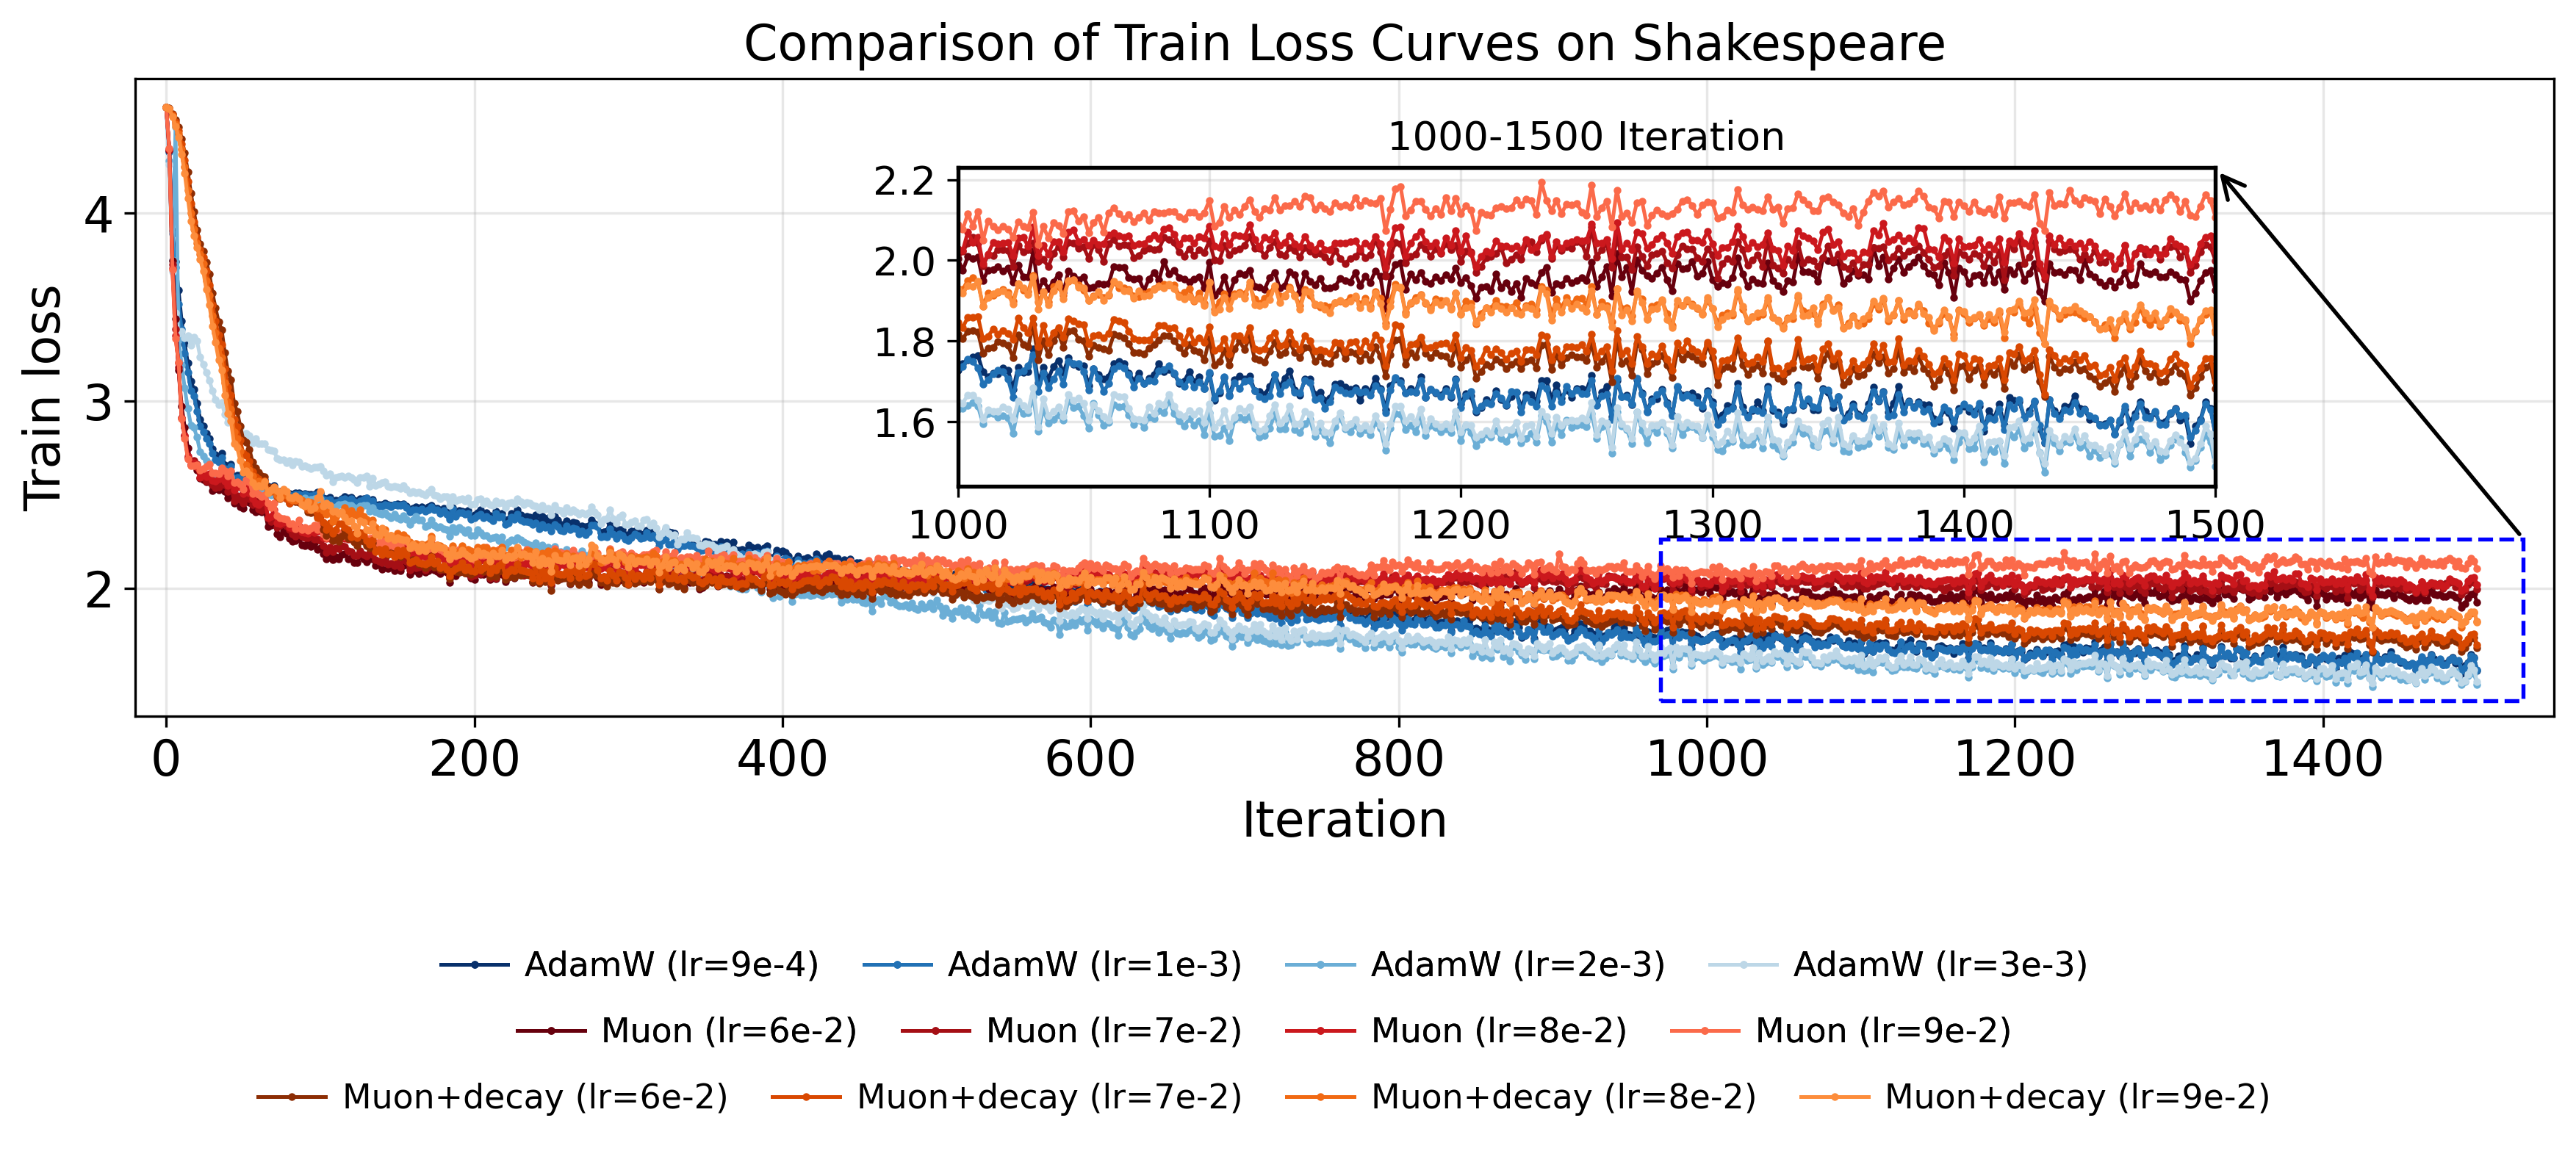

Saved figure to: llm_pretrain_motivation_shakespeare_train.pdf


In [8]:
fig, ax = plt.subplots(figsize=(12, 5))

train_curves = []
for name in methods:
    x, y = get_curve(df_train, x_col, col_map_train[name])
    train_curves.append((name, x, y))
    ax.plot(x, y, marker="o", markersize=1.5, linewidth=1.2, label=name, color=colors[name])

ax.set_title("Comparison of Train Loss Curves on Shakespeare", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Train loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)

max_iter = int(df_train[x_col].max())
ax.set_xlim(-20.0, float(max_iter) + 50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter

axins = ax.inset_axes([0.34, 0.36, 0.52, 0.50])
for name, x, y in train_curves:
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)

axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)

for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)

all_inset_vals = []
for name, x, y in train_curves:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])

vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin

rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0,
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)

arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),
    coordsA=ax.transData,
    xyB=(1.0, 1.0),
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black",
    shrinkA=2, shrinkB=2, clip_on=False,
)
fig.add_artist(arrow)

fig.tight_layout()
fig.subplots_adjust(bottom=0.34)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = methods[:4]
row2 = methods[4:8]
row3 = methods[8:12]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=11, bbox_to_anchor=(0.5, 0.07), columnspacing=1.3, handletextpad=0.5)
fig.add_artist(leg1)
leg2 = fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
                  fontsize=11, bbox_to_anchor=(0.5, 0.01), columnspacing=1.3, handletextpad=0.5)
fig.add_artist(leg2)
fig.legend([hmap[l] for l in row3], row3, loc="lower center", ncol=len(row3), frameon=False,
           fontsize=11, bbox_to_anchor=(0.5, -0.05), columnspacing=1.3, handletextpad=0.5)

plt.show()
fig.savefig("llm_pretrain_motivation_shakespeare_train.pdf", dpi=300, format="pdf", bbox_inches="tight")
print("Saved figure to: llm_pretrain_motivation_shakespeare_train.pdf")
plt.close()

### Train loss curves with learning-rate range

For each optimizer, the solid curve is the mean over its four learning rates. The shaded area is the pointwise range from the minimum to the maximum loss across the four learning rates.

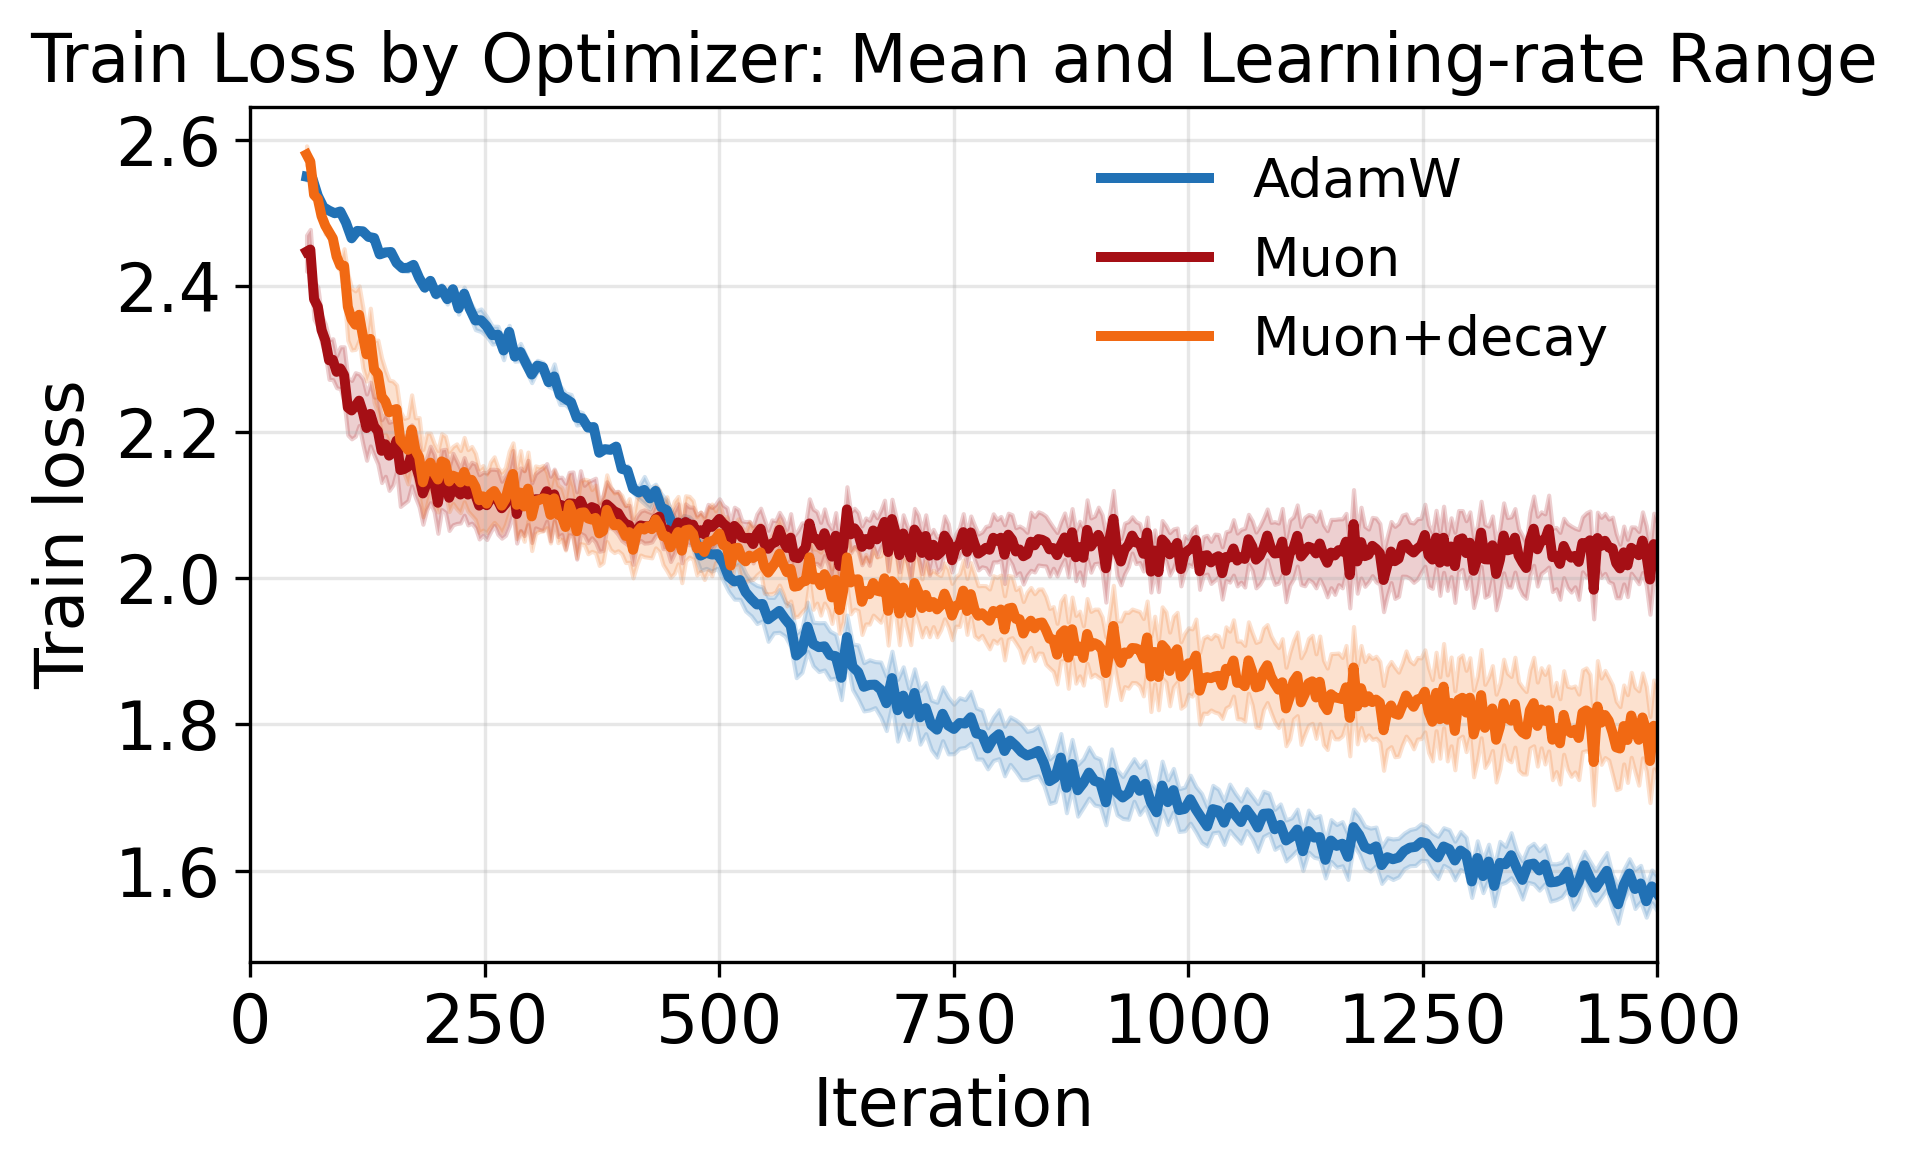

Saved figure to: llm_pretrain_motivation_shakespeare_train_seaborn.pdf


In [129]:
optimizer_groups = {
    "AdamW": methods[:4],
    "Muon": methods[4:8],
    "Muon+decay": methods[8:12],
}

def build_seaborn_data(
    df,
    col_map,
    methods,                # 
    group_name,             # 
    iter_start=None,        # Inclusive lower bound on the "iter" axis.
    iter_end=None,          # Inclusive upper bound on the "iter" axis.
    exclude_ranges=None,    # List of (start, end) inclusive intervals to drop,
                            # e.g. [(1000, 1200), (3000, 3100)].
    stride=1,               # Down-sampling stride: keep every `stride`-th point.
    smooth_window=1,        # Centered rolling-mean window size; 1 disables smoothing.
):
    """
    Build the long-format DataFrame consumed by seaborn.lineplot.

    Each row corresponds to one (iter, loss) sample tagged with its
    optimizer group and the specific learning-rate run it came from.

    Parameters
    ----------
    df : pd.DataFrame
        Raw data source.
    col_map : dict[str, str]
        Mapping from run name (e.g. "AdamW (lr=1e-3)") to CSV column name.
    iter_start : float, optional
        Keep only samples with iter >= iter_start.
    iter_end : float, optional
        Keep only samples with iter <= iter_end.
    exclude_ranges : list[tuple[float, float]], optional
        List of inclusive [start, end] intervals to drop from every curve.
        Useful for masking out known-bad segments (e.g. restarts, warmup).
    stride : int, default 1
        Down-sampling factor. stride=10 keeps every 10th point.
    smooth_window : int, default 1
        Window size for a centered rolling mean applied to the loss before
        down-sampling. Values > 1 produce smoother curves; combine with
        `stride` to approximate "average every N points".

    Returns
    -------
    pd.DataFrame
        Columns: ["iter", "loss", "optimizer", "learning_rate"].
    """
    if exclude_ranges is None:
        exclude_ranges = []

    all_data = []
    for name in methods:
        x, y = get_curve(df, x_col, col_map[name])
        if len(x) == 0:
            continue

        # 1. Trim by iter value (inclusive bounds on both ends).
        mask = np.ones(len(x), dtype=bool)
        if iter_start is not None:
            mask &= x >= iter_start
        if iter_end is not None:
            mask &= x <= iter_end

        # 2. Drop excluded intervals.
        for ex_start, ex_end in exclude_ranges:
            mask &= ~((x >= ex_start) & (x <= ex_end))

        x, y = x[mask], y[mask]
        if len(x) == 0:
            continue

        # 3. Optional smoothing via centered rolling mean.
        if smooth_window and smooth_window > 1:
            y = (
                pd.Series(y)
                .rolling(window=smooth_window, center=True, min_periods=1)
                .mean()
                .to_numpy()
            )

        # 4. Optional down-sampling.
        if stride and stride > 1:
            x = x[::stride]
            y = y[::stride]

        data = pd.DataFrame({"iter": x, "loss": y})
        data["optimizer"] = group_name
        data["learning_rate"] = name
        all_data.append(data)

    if not all_data:
        return pd.DataFrame(columns=["iter", "loss", "optimizer", "learning_rate"])
    return pd.concat(all_data, ignore_index=True)

groups_train = [
    ("AdamW",       methods[:4],  dict(iter_start=60, stride=3, smooth_window=3)),
    ("Muon",        methods[4:8], dict(iter_start=60, stride=2, smooth_window=2)),
    ("Muon+decay",  methods[8:12],dict(iter_start=60, stride=2, smooth_window=2)),
]

fig, ax = plt.subplots(figsize=(6, 4))
for gname, mlist, kw in groups_train:
    train_seaborn_data = build_seaborn_data(df_train, col_map_train, mlist, gname, **kw)
    if gname == "AdamW":
        sns.lineplot(
            data=train_seaborn_data,
            x="iter",
            y="loss",
            hue="optimizer",
            estimator="median",
            errorbar=("pi", 25),
            err_style="band",
            err_kws={"alpha": 0.2},  # for band
            palette={
                "AdamW": colors["AdamW"],
            },
            linewidth=2.4,
            ax=ax,
        )
    elif gname == "Muon+decay":
        sns.lineplot(
            data=train_seaborn_data,
            x="iter",
            y="loss",
            hue="optimizer",
            estimator="mean",
            errorbar=("pi", 50),
            err_style="band",
            err_kws={"alpha": 0.2},
            palette={
                "Muon+decay": colors["Muon+decay"],
            },
            linewidth=2.4,
            ax=ax,
        )
    elif gname == "Muon":
        sns.lineplot(
            data=train_seaborn_data,
            x="iter",
            y="loss",
            hue="optimizer",
            estimator="mean",
            errorbar=("pi", 60),
            err_style="band",
            err_kws={"alpha": 0.2},
            palette={
                "Muon": colors["Muon"],
            },
            linewidth=2.4,
            ax=ax,
        )

ax.set_title("Train Loss by Optimizer: Mean and Learning-rate Range", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Train loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
ax.set_xlim(0.0, float(df_train[x_col].max()))
#ax.set_xscale('asinh', linear_width=1)
#ax.set_xscale('log', base=2)
#ax.set_xscale('logit')
ax.set_xscale('linear')
#ax.set_yscale("symlog", linthresh=0.5, linscale=1.0)
ax.legend(title=None, fontsize=13, frameon=False)

fig.tight_layout()
plt.show()
fig.savefig("llm_pretrain_motivation_shakespeare_train_seaborn.pdf", dpi=300, format="pdf", bbox_inches="tight")
print("Saved figure to: llm_pretrain_motivation_shakespeare_train_seaborn.pdf")
plt.close()

### Validation loss curves with learning-rate range

For each optimizer, the solid curve is the mean over its four learning rates. The shaded area is the pointwise range from the minimum to the maximum loss across the four learning rates.

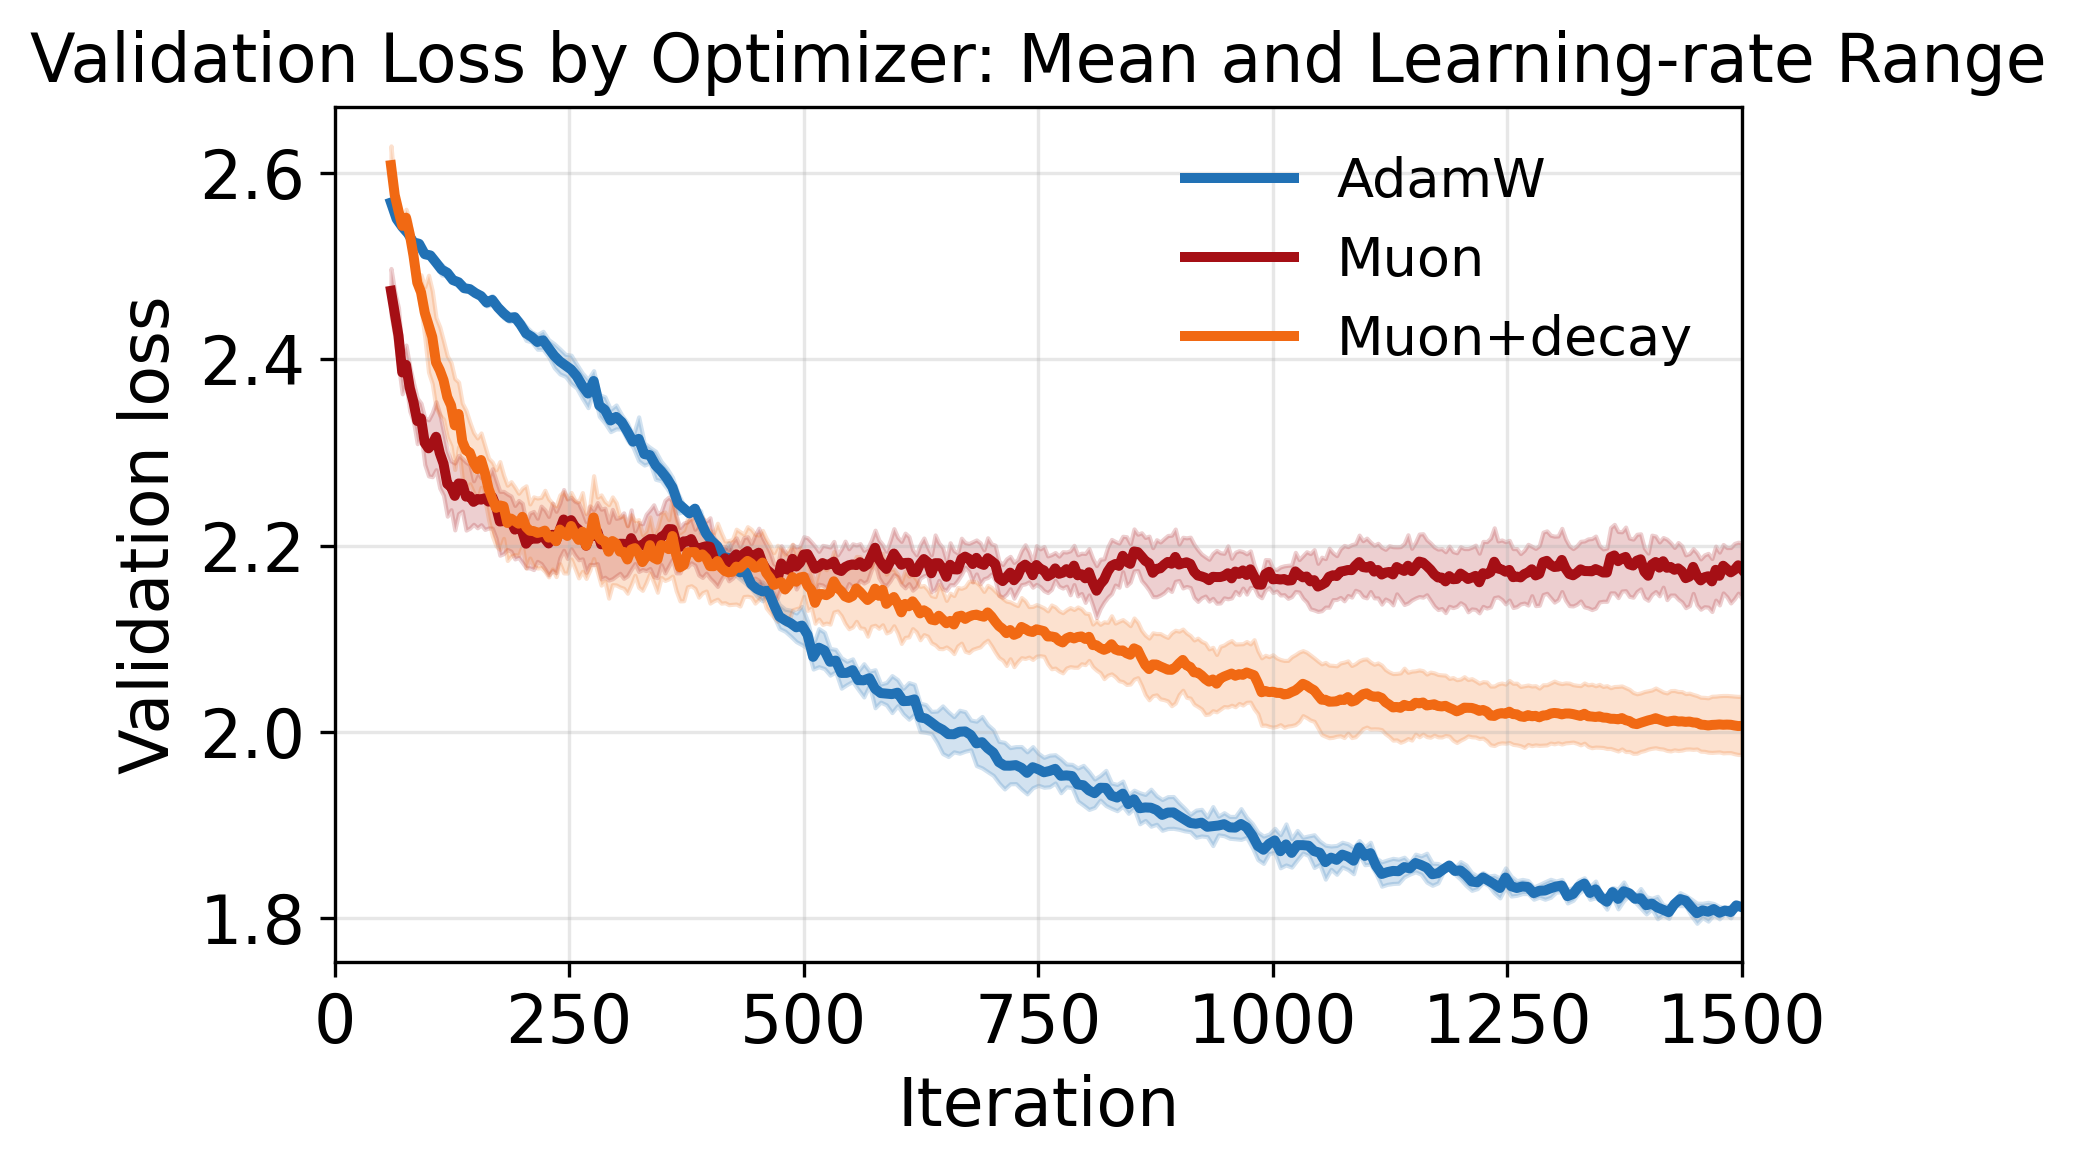

Saved figure to: llm_pretrain_motivation_shakespeare_val_seaborn.pdf


In [130]:
groups_val = [
    ("AdamW",       methods[:4],  dict(iter_start=60, stride=3, smooth_window=3)),
    ("Muon",        methods[4:8], dict(iter_start=60, stride=2, smooth_window=2)),
    ("Muon+decay",  methods[8:12],dict(iter_start=60, stride=2, smooth_window=2)),
]

fig, ax = plt.subplots(figsize=(6, 4))
for gname, mlist, kw in groups_val:
    val_seaborn_data = build_seaborn_data(df_val, col_map_val, mlist, gname, **kw)
    if gname == "AdamW":
        sns.lineplot(
            data=val_seaborn_data,
            x="iter",
            y="loss",
            hue="optimizer",
            estimator="median",
            errorbar=("pi", 30),
            err_style="band",
            err_kws={"alpha": 0.2},  # for band
            palette={
                "AdamW": colors["AdamW"],
            },
            linewidth=2.4,
            ax=ax,
        )
    elif gname == "Muon+decay":
        sns.lineplot(
            data=val_seaborn_data,
            x="iter",
            y="loss",
            hue="optimizer",
            estimator="mean",
            errorbar=("pi", 70),
            err_style="band",
            err_kws={"alpha": 0.2},
            palette={
                "Muon+decay": colors["Muon+decay"],
            },
            linewidth=2.4,
            ax=ax,
        )
    elif gname == "Muon":
        sns.lineplot(
            data=val_seaborn_data,
            x="iter",
            y="loss",
            hue="optimizer",
            estimator="mean",
            errorbar=("pi", 60),
            err_style="band",
            err_kws={"alpha": 0.2},
            palette={
                "Muon": colors["Muon"],
            },
            linewidth=2.4,
            ax=ax,
        )

ax.set_title("Validation Loss by Optimizer: Mean and Learning-rate Range", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Validation loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
ax.set_xlim(0.0, float(df_val[x_col].max()))
ax.set_xscale('linear')
ax.legend(title=None, fontsize=13, frameon=False)

fig.tight_layout()
plt.show()
fig.savefig("llm_pretrain_motivation_shakespeare_val_seaborn.pdf", dpi=300, format="pdf", bbox_inches="tight")
print("Saved figure to: llm_pretrain_motivation_shakespeare_val_seaborn.pdf")
plt.close()